# EDA -> DSC PJATK Catalogue Quality Challenge

Sprawdzam czym oferty z błędem (target 1) różnią się od poprawnych (target 0)

Dane: train.csv (16 000 ofert z odpowiedzią), test.csv (10 000 bez odpowiedzi) i oof_tree_v2.csv od Piotra do analizy pomyłek

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
oof = pd.read_csv("../data/handoff/oof_tree_v2.csv")

# True tylko w prywatnej wersji, pokazuje konkretne oferty
SHOW_EXAMPLES = False

In [2]:
train.shape, test.shape, oof.shape

((16000, 11), (10000, 10), (16000, 5))

In [3]:
if SHOW_EXAMPLES:
    display(train.head())
train.dtypes

id                     object
seller_id              object
title                  object
description            object
declared_category      object
brand                  object
condition              object
price_pln             float64
shipping_weight_kg    float64
pack_size             float64
target                  int64
dtype: object

In [4]:
train["target"].value_counts(normalize=True).map("{:.1%}".format)

target
0    83.0%
1    17.0%
Name: proportion, dtype: object

83% ofert jest ok a 17% ma błąd

## Braki danych

In [5]:
train.isna().mean().map("{:.1%}".format).sort_values(ascending=False)

shipping_weight_kg    6.0%
brand                 5.9%
description           4.2%
price_pln             3.9%
pack_size             3.0%
title                 2.9%
declared_category     2.3%
id                    0.0%
seller_id             0.0%
condition             0.0%
target                0.0%
dtype: object

In [6]:
missing_by_target = train.isna().groupby(train["target"]).mean().T.sort_values(1, ascending=False)
missing_by_target.map("{:.1%}".format)

target,0,1
shipping_weight_kg,6.0%,6.2%
brand,6.0%,5.4%
price_pln,3.8%,4.3%
description,4.4%,3.7%
pack_size,3.0%,3.2%
title,3.0%,2.6%
declared_category,2.3%,2.5%
seller_id,0.0%,0.0%
id,0.0%,0.0%
condition,0.0%,0.0%


Braki to 2-6% wartości, najwięcej waga i marka. W poprawnych i błędnych ofertach jest ich tyle samo, więc braki nie wskazują błędu

## Kategorie

In [7]:
categories = (
    train.groupby("declared_category", dropna=False)["target"]
    .agg(odsetek_bledow="mean", liczba_ofert="count")
    .sort_values("odsetek_bledow", ascending=False)
)
categories["odsetek_bledow"] = categories["odsetek_bledow"].map("{:.1%}".format)
categories

,odsetek_bledow,liczba_ofert
declared_category,,
music,36.6%,735
garden,21.1%,1331
NaN,18.2%,374
kitchen,17.3%,2253
pets,17.3%,863
computers,16.0%,2759
beauty,15.9%,1622
audio,15.0%,2535
sport,14.0%,1837


In [8]:
if SHOW_EXAMPLES:
    display(train[(train["declared_category"] == "music") & (train["target"] == 1)][["title", "declared_category"]].head(10))

Music ma 37% błędów (średnio 17%). W błędnych ofertach music są np. SSD, słuchawki i książki, czyli kategoria nie pasuje do produktu. Tekst jest brudny: literówki, dziwne spacje i różne zapisy liczby sztuk

In [9]:
if SHOW_EXAMPLES:
    display(train[(train["declared_category"] == "music") & (train["target"] == 0)][["title", "declared_category"]].head(10))

Poprawne oferty music to naprawdę sprzęt muzyczny (mikrofony, nuty, perkusja). W błędnych kategoria często nie pasuje do produktu, ale z samego targetu nie wiem co dokładnie zepsuł generator

## Ceny

In [10]:
train.groupby("target")["price_pln"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,12773.0,138.20,182.78,2.75,40.16,77.25,162.11,3049.33
1,2604.0,181.16,316.29,0.97,36.89,79.81,192.25,3464.27


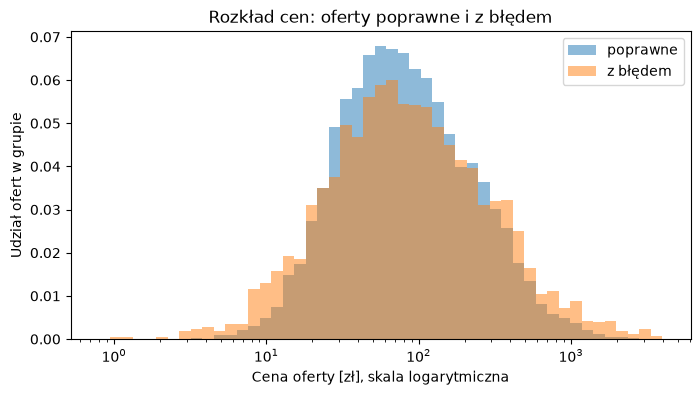

In [11]:
labels = {0: "poprawne", 1: "z błędem"}
# skala log, inaczej tanie oferty zlewają się przy zerze
bins = np.logspace(-0.1, 3.6, 50)

plt.figure(figsize=(8, 4))
for target_value in [0, 1]:
    prices = train.loc[train["target"] == target_value, "price_pln"].dropna()
    # udział w grupie zamiast liczby ofert
    weights = np.ones(len(prices)) / len(prices)
    plt.hist(prices, bins=bins, weights=weights, alpha=0.5, label=labels[target_value])

plt.xscale("log")
plt.xlabel("Cena oferty [zł], skala logarytmiczna")
plt.ylabel("Udział ofert w grupie")
plt.title("Rozkład cen: oferty poprawne i z błędem")
plt.legend()
plt.show()

Mediana cen jest podobna, ale błędne oferty częściej mają bardzo niską albo bardzo wysoką cenę

### Cena względem kategorii

Cena podzielona przez medianę ceny w kategorii (1 = typowa cena)

In [12]:
category_median = train.groupby("declared_category")["price_pln"].transform("median")
train["price_vs_category"] = train["price_pln"] / category_median
train.groupby("target")["price_vs_category"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,12475.0,1.48,1.63,0.05,0.56,0.99,1.78,30.89
1,2539.0,1.97,3.24,0.03,0.50,1.05,2.18,61.02


### Ile ofert ma skrajną cenę

Skrajna = ponad 5x albo poniżej 0.2x mediany kategorii (próg wybrałem sam)

Liczę tylko oferty, które mają cenę i kategorię

In [13]:
extrema_price = (train["price_vs_category"] > 5) | (train["price_vs_category"] < 0.2)
# bez braków
extrema_price = extrema_price[train["price_vs_category"].notna()]
extrema_price.groupby(train["target"]).mean().map("{:.1%}".format)

target
0     6.0%
1    14.8%
Name: price_vs_category, dtype: object

### Cena za sztukę względem kategorii

Cena jest za całą paczkę, więc dzielę ją przez pack_size

In [14]:
train["price_per_item"] = train["price_pln"] / train["pack_size"]
item_median = train.groupby("declared_category")["price_per_item"].transform("median")
train["item_price_vs_category"] = train["price_per_item"] / item_median
train.groupby("target")["item_price_vs_category"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,12098.0,1.31,1.10,0.07,0.60,1.01,1.67,16.35
1,2455.0,1.65,2.18,0.03,0.42,0.91,2.03,30.94


In [15]:
extrema_item = (train["item_price_vs_category"] > 5) | (train["item_price_vs_category"] < 0.2)
# bez braków
extrema_item = extrema_item[train["item_price_vs_category"].notna()]
extrema_item.groupby(train["target"]).mean().map("{:.1%}".format)

target
0     3.1%
1    15.4%
Name: item_price_vs_category, dtype: object

Cena za sztukę: skrajną ma 3.1% poprawnych i 15.4% błędnych (cena paczki: 6.0% i 14.8%). Dwa razy mniej fałszywych alarmów, więc cena za sztukę działa lepiej. Pominięte ok. 1 450 ofert bez ceny, kategorii lub pack_size (przy cenie paczki ok. 990)

## Waga za sztukę względem kategorii

In [16]:
train["weight_per_item"] = train["shipping_weight_kg"] / train["pack_size"]
weight_median = train.groupby("declared_category")["weight_per_item"].transform("median")
train["item_weight_vs_category"] = train["weight_per_item"] / weight_median
train.groupby("target")["item_weight_vs_category"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,11835.0,1.8,2.21,0.09,0.62,1.00,2.03,19.68
1,2405.0,2.1,3.83,0.03,0.45,0.95,2.14,53.07


In [17]:
extrema_weight = (train["item_weight_vs_category"] > 5) | (train["item_weight_vs_category"] < 0.2)
# bez braków
extrema_weight = extrema_weight[train["item_weight_vs_category"].notna()]
extrema_weight.groupby(train["target"]).mean().map("{:.1%}".format)

target
0     9.1%
1    17.1%
Name: item_weight_vs_category, dtype: object

Waga za sztukę: skrajną ma 9.1% poprawnych i 17.1% błędnych, czyli słabiej niż cena. Pewnie dlatego, że waga jest z opakowaniem i produkty mają różne rozmiary. Pominięte ok. 1 760 ofert

## Liczba sztuk w opisie a pack_size

In [18]:
import sys
sys.path.append("..")
from model_tree_v2 import counts_v2

# liczba sztuk z tytułu i opisu
text_counts = [counts_v2(t) | counts_v2(d) for t, d in zip(train["title"], train["description"])]
train["text_quantity"] = [next(iter(c)) if len(c) == 1 else np.nan for c in text_counts]
train["text_quantity"].notna().mean()

np.float64(0.999375)

In [19]:
# ile ofert ma inną liczbę w tekście niż pack_size
known = train["text_quantity"].notna() & train["pack_size"].notna()
mismatch = train.loc[known, "text_quantity"] != train.loc[known, "pack_size"]
mismatch.groupby(train.loc[known, "target"]).mean().map("{:.1%}".format)

target
0     0.0%
1    14.9%
dtype: object

In [20]:
# przykłady
if SHOW_EXAMPLES:
    display(train.loc[known][mismatch][["title", "pack_size", "text_quantity", "target"]].head(10))

Liczbę sztuk z tekstu da się odczytać w 99.9% ofert. Inna liczba niż w pack_size jest w 0.0% poprawnych i 14.9% błędnych. W tym treningu i z tym parserem to zawsze błąd, ale nie ma gwarancji że w nowych danych też. Najmocniejszy sygnał, ale łapie tylko część błędów

## Porównanie: cechy liczby sztuk z tekstu

Sprawdzam czy cechy liczby sztuk z tekstu pomagają modelowi. Zmieniam tylko tę grupę cech, reszta (model, ustawienia, dane, foldy) jak w tree_v2

In [21]:
import time
from sklearn.metrics import roc_auc_score
import model_tree_v2 as m

raw = pd.read_csv("../data/train.csv")
y = raw["target"].to_numpy()
x = m.rich_features(raw.drop(columns="target"))
folds = m.canonical_folds(raw)["fold"].to_numpy()

In [22]:
quantity_cols = ["text_pack", "pack_difference", "quantity_title_v2", "quantity_desc_v2", "quantity_conflict_v2", "quantity_missing_v2", "pack_ratio_v2",
                 "price_per_text_item", "weight_per_text_item"]
with_quantity = m.RICH_NUMERIC
without_quantity = [c for c in m.RICH_NUMERIC if c not in quantity_cols]
assert all(c in m.RICH_NUMERIC for c in quantity_cols), "literówka w quantity_cols"
len(with_quantity), len(without_quantity)

(24, 15)

In [23]:
def make_model(numeric_cols):
    original = m.RICH_NUMERIC
    m.RICH_NUMERIC = numeric_cols
    model = m.make_tree_model()
    m.RICH_NUMERIC = original
    return model

In [24]:
def run_cv(numeric_cols):
    oof = np.full(len(raw), np.nan)
    fold_auc = {}
    start = time.perf_counter()
    for fold in range(1, 6):
        fit, valid = folds != fold, folds == fold
        model = make_model(numeric_cols)
        model.fit(x[fit], y[fit])
        oof[valid] = model.predict_proba(x[valid])[:, 1]
        fold_auc[fold] = roc_auc_score(y[valid], oof[valid])
    return oof, fold_auc, roc_auc_score(y, oof), time.perf_counter() - start

In [25]:
# 4 wątki tak jak u piotra bo inaczej wynik trochę skacze
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=4):
    oof_with, folds_with, auc_with, time_with = run_cv(with_quantity)
    oof_without, folds_without, auc_without, time_without = run_cv(without_quantity)

comparison = pd.DataFrame({"z cechami ilości": folds_with, "bez cech ilości": folds_without})
comparison.loc["OOF łącznie"] = [auc_with, auc_without]
comparison.loc["czas [s]"] = [time_with, time_without]
comparison["różnica"] = comparison["z cechami ilości"] - comparison["bez cech ilości"]
comparison.round(4)

,z cechami ilości,bez cech ilości,różnica
1,0.9108,0.8807,0.0301
2,0.9128,0.8841,0.0286
3,0.9189,0.8838,0.0351
4,0.9119,0.8857,0.0262
5,0.9201,0.8978,0.0223
OOF łącznie,0.9150,0.8863,0.0287
czas [s],7.2709,6.4046,0.8663


In [26]:
# wersje bibliotek na których to policzyłem
import scipy, sklearn, threadpoolctl
print("python", sys.version.split()[0])
for lib in [np, pd, sklearn, scipy, threadpoolctl]:
    print(lib.__name__, lib.__version__)

python 3.14.7
numpy 2.5.4
pandas 2.3.3
sklearn 1.9.1
scipy 1.18.1
threadpoolctl 3.7.0


In [27]:
# oof ma target z traina więc idzie do outputs (gitignore)
import os
os.makedirs("../outputs", exist_ok=True)
pd.DataFrame({"id": raw["id"], "fold": folds, "target": y,
              "oof_with": oof_with, "oof_without": oof_without}).to_csv("../outputs/quantity_comparison_oof.csv", index=False)
comparison.to_csv("../quantity_comparison.csv")

Z cechami liczby sztuk OOF AUC 0.9150, bez nich 0.8863 (+0.029). Lepiej w każdym z 5 foldów. Policzone na Python 3.14.7, numpy 2.5.4, pandas 2.3.3, scikit-learn 1.9.1. U Piotra (scikit-learn 1.6.1) tree_v2 ma 0.9137, pewnie przez inne wersje. Minus: tekst i tak idzie do modelu przez TF-IDF, więc model bez tych cech może coś z niego wyczytać

## Porównanie: kategoria i tekst (Piotr)

Z notebooka 02_Eksperyment_kategoria. Piotr sprawdził połączenia kategorii ze słowami z tekstu (np. audio__headphones). Model to regresja logistyczna, zmieniona tylko ta grupa cech

In [28]:
category_comparison = pd.read_csv("../category_comparison.csv", index_col="configuration")
category_comparison.round(4)

,fold_1,fold_2,fold_3,fold_4,fold_5,oof_roc_auc,seconds,delta_vs_reference
configuration,,,,,,,,
with_category_text,0.7113,0.6951,0.7257,0.7230,0.7299,0.7177,14.8359,0.0
without_category_text,0.6130,0.6123,0.6080,0.6261,0.6290,0.6177,9.6516,-0.1


Z połączeniami OOF AUC 0.7177, bez nich 0.6177 (-0.100), gorzej w każdym foldzie. To wynik dla regresji, nie dla tree_v2, i nie znaczy że każda niepasująca kategoria to błąd

## Analiza 5 pomyłek

Oceniam OOF modelu tree_v2. Reguła: sprawdzamy tyle ofert, ile średnio jest błędnych (17%), czyli te z najwyższym wynikiem modelu

In [29]:
cols = ["id", "title", "description", "declared_category", "price_pln", "shipping_weight_kg", "pack_size"]
analysis = oof.merge(train[cols], on="id")

In [30]:
budget = analysis["target"].mean()
threshold = analysis["prediction"].quantile(1 - budget)
analysis["decision"] = (analysis["prediction"] >= threshold).astype(int)
threshold

np.float64(0.19767602016281982)

In [31]:
pd.crosstab(analysis["target"], analysis["decision"], rownames=["prawda"], colnames=["decyzja"])

decyzja,0,1
prawda,,
0,12601,678
1,678,2043


In [32]:
fp = analysis[(analysis["target"] == 0) & (analysis["decision"] == 1)].sort_values("prediction", ascending=False)
if SHOW_EXAMPLES:
    display(fp.head(5))
len(fp)

678

In [33]:
fn = analysis[(analysis["target"] == 1) & (analysis["decision"] == 0)].sort_values("prediction")
if SHOW_EXAMPLES:
    display(fn.head(5))
len(fn)

678

### Zakresy dla 5 przypadków

Grupa porównawcza: poprawne oferty z tym samym produktem w tytule, bez samej oferty. Obok stosunek do mediany kategorii dla porównania

In [34]:
# grupa porównawcza: poprawne oferty z tym samym produktem w tytule (bez samej oferty)
title = train["title"].str.lower().str.split().str.join(" ")
# cooking scr bo w tytułach jest literówka scrper
cases = {"1 FP": (fp.iloc[0], "dumbbell"), "2 FP": (fp.iloc[1], "cooking scr"), "3 FP": (fp.iloc[2], "travel guide"),
         "4 FN": (fn.iloc[0], "frying pan"), "5 FN": (fn.iloc[1], "piano score")}
ranges = {}
for name, (case, product) in cases.items():
    offer = train[train["id"] == case["id"]].iloc[0]
    group = train[(train["target"] == 0) & title.str.contains(product, na=False) & (train["id"] != case["id"])]
    ranges[f"{name} {product}"] = {
        "wynik modelu": case["prediction"],
        "ofert w grupie": len(group),
        "cena/szt": offer["price_per_item"],
        "cena/szt min": group["price_per_item"].min(),
        "cena/szt mediana": group["price_per_item"].median(),
        "cena/szt max": group["price_per_item"].max(),
        "cena/szt vs kategoria": offer["item_price_vs_category"],
        "waga/szt": offer["weight_per_item"],
        "waga/szt min": group["weight_per_item"].min(),
        "waga/szt mediana": group["weight_per_item"].median(),
        "waga/szt max": group["weight_per_item"].max(),
        "waga/szt vs kategoria": offer["item_weight_vs_category"],
    }
pd.DataFrame(ranges).round(2)

,1 FP dumbbell,2 FP cooking scr,3 FP travel guide,4 FN frying pan,5 FN piano score
wynik modelu,0.83,0.81,0.78,0.02,0.02
ofert w grupie,79.00,79.00,82.00,78.00,75.00
cena/szt,55.76,5.37,13.12,46.50,44.45
cena/szt min,20.63,7.43,18.35,43.47,10.67
cena/szt mediana,86.98,19.93,45.19,98.98,51.31
cena/szt max,199.53,38.60,118.22,210.01,107.23
cena/szt vs kategoria,NaN,0.10,0.26,0.90,0.89
waga/szt,6.30,0.11,0.40,0.35,0.75
waga/szt min,1.68,0.07,0.27,0.60,0.16
waga/szt mediana,3.20,0.12,0.43,0.96,0.32


In [35]:
# promocja w poprawnych i błędnych ofertach (cecha z tree_v2)
x["promotion_mentioned"].groupby(y).mean().map("{:.1%}".format)

0    9.3%
1    9.3%
Name: promotion_mentioned, dtype: object

### Przypadek 1 (FP)

wynik 0.83 -> uznana za błędną

Hantle 5 szt, bez kategorii i opisu. 6.3 kg na sztukę, a inne poprawne hantle ważą 1.7-5.7 kg (mediana 3.2). Waga jest najwyższa w grupie, ale oferta jest ok. Bez kategorii model nie ma jej z czym porównać

Test: dodać cechę waga za sztukę / mediana tego samego produktu z tytułu (mediana liczona tylko na części treningowej foldu) i sprawdzić AUC na tych samych foldach. Tu wyszłoby ok. 2x mediany, czyli nic bardzo skrajnego

### Przypadek 2 (FP)

wynik 0.81 -> uznana za błędną

Szpatułka za 5.37 zł, inne poprawne szpatułki kosztują 7.4-38.6 zł (mediana 19.9). Taniej niż wszystkie, a na tle kategorii kitchen to 0.1x mediany. W opisie jest promocja. Model ma cechę promotion_mentioned, ale promocja jest w 9.3% poprawnych i 9.3% błędnych ofert, więc sama nic nie mówi. Model musiałby połączyć promocję z niską ceną i tutaj tego nie zrobił

Test: policzyć ile ofert z promocją i ceną poniżej 0.3x mediany produktu jest poprawnych, a ile błędnych. Jeśli prawie same poprawne, dodać cechę niska cena i promocja naraz

### Przypadek 3 (FP)

wynik 0.78 -> uznana za błędną

Przewodnik za 13.12 zł, inne poprawne przewodniki kosztują 18.4-118.2 zł (mediana 45.2). Tak samo jak w przypadku 2: najtańszy w grupie i z promocją w opisie

Test: sprawdzić o ile promocja obniża cenę w poprawnych ofertach tego samego produktu (mediana z promocją / mediana bez promocji). Tu cena to ok. 0.3x mediany, jeśli promocje zwykle tak obniżają to taka cena jest normalna

### Przypadek 4 (FN)

wynik 0.02 -> przepuszczona

Patelnie 3 szt, 0.35 kg na sztukę, a inne poprawne patelnie ważą 0.6-1.6 kg (mediana 0.96). Lżejsze niż wszystkie, ale na tle całej kategorii kitchen to 0.92x mediany, więc nic nie odstaje i model tego nie widzi. Cena za sztukę 46.5 zł też jest blisko dolnej granicy (43.5-210 zł)

Test: ta sama cecha co w przypadku 1 (waga względem produktu z tytułu). Tu wyszłoby ok. 0.36x mediany, czyli mocno odstaje. Sprawdzić AUC z tą cechą i bez niej

### Przypadek 5 (FN)

wynik 0.02 -> przepuszczona

Nuty na pianino w books. 0.75 kg, a inne poprawne nuty ważą 0.16-0.5 kg (mediana 0.32). Cięższe niż wszystkie, ale na tle books to 1.44x mediany, więc nic nie odstaje. Nie wiem co dokładnie zmienił generator, widać tylko że waga nie pasuje do produktu

Test: nuty są w books i w music, więc mediana kategorii tu nie pomoże. Sprawdzić ile błędnych i ile poprawnych ofert ma wagę poza zakresem swojego produktu z tytułu. Jeśli dużo więcej błędnych, to grupa z tytułu jest lepsza niż kategoria

Wybrałem 3 najpewniejsze fałszywe alarmy i 2 najbardziej przeoczone błędy. Fałszywe alarmy to oferta bez kategorii z wysoką wagą i dwie tanie oferty w promocji. Przeoczenia mają wagę nietypową dla produktu, ale normalną dla kategorii. Pomysł: porównywać cenę i wagę z tym samym produktem z tytułu i łączyć niską cenę z promocją

## Wnioski

- 17% ofert ma błąd
- braki nie wskazują błędu
- music 37% błędów, w błędnych kategoria często nie pasuje do produktu
- tekst brudny, liczba sztuk zapisana na wiele sposobów
- cena za sztukę: 3.1% vs 15.4% skrajnych, lepiej niż cena paczki
- waga za sztukę: 9.1% vs 17.1%, słabiej niż cena
- inna liczba sztuk w tekście niż pack_size tylko w błędnych (0% vs 14.9%), ale to wynik z tego treningu i tego parsera
- cechy liczby sztuk podnoszą AUC z 0.8863 do 0.9150 (tree_v2)
- połączenia kategorii z tekstem podnoszą AUC z 0.6177 do 0.7177 (regresja logistyczna, Piotr)
- pomyłki modelu: fałszywe alarmy to tanie oferty w promocji i oferta bez kategorii, przeoczenia mają wagę nietypową dla produktu ale normalną dla kategorii

## Ograniczenia

- pominięte oferty bez ceny, wagi, kategorii lub pack_size
- progi 5x i 0.2x wybrane na oko
- zła kategoria psuje porównanie z medianą
- target mówi tylko że jest błąd, nie mówi co dokładnie zmienił generator
- grupa z tytułu łapie tylko jedną nazwę produktu, synonimy i część literówek odpadają
- 5 przypadków to przykłady, nie statystyka